In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Part 1, Question 1
arr = np.arange(50)
reshaped_arr = np.reshape(arr, (10, 5))
reshaped_arr.shape

(10, 5)

In [26]:
# Question 2
selected_rows = reshaped_arr[reshaped_arr[:, 0] > 20]
selected_rows

array([[25, 26, 27, 28, 29],
       [30, 31, 32, 33, 34],
       [35, 36, 37, 38, 39],
       [40, 41, 42, 43, 44],
       [45, 46, 47, 48, 49]])

In [29]:
# Question 3
# Mean of each column:
mean_columns = reshaped_arr.mean(axis=0)
print(mean_columns)
mean_rows = reshaped_arr.mean(axis=1)
print(mean_rows)
print('Axis is the dimension that the array collapses: 0 means collapse vertically to one row and 1 means collapse horizontally to one column')

[22.5 23.5 24.5 25.5 26.5]
[ 2.  7. 12. 17. 22. 27. 32. 37. 42. 47.]
Axis is the dimension that the array collapses: 0 means collapse vertically to one row and 1 means collapse horizontally to one column


In [30]:
# Question 4
arr_2 = np.linspace(0, np.pi * 4, 100)
sin_arr2 = np.sin(arr_2)
positive_sin_arr2 = np.sum(sin_arr2 > 0)
positive_sin_arr2

np.int64(49)

In [32]:
# Part 2
url = "https://gml.noaa.gov/webdata/ccgg/trends/co2/co2_mm_mlo.csv"
co2 = pd.read_csv(url, comment="#")
co2 = co2.rename(columns={"decimal date": "decimal_date"})

# Build a proper datetime column (measurements are monthly means, dated mid-month).
co2["date"] = pd.to_datetime(dict(year=co2["year"], month=co2["month"], day=15))

# NOAA codes missing monthly means as -99.99.
co2 = co2[co2["average"] > 0].reset_index(drop=True)

co2.head()

,year,month,decimal_date,average,deseasonalized,ndays,sdev,unc,date
0,1958,3,1958.2027,315.71,314.44,-1,-9.99,-0.99,1958-03-15
1,1958,4,1958.2877,317.45,315.16,-1,-9.99,-0.99,1958-04-15
2,1958,5,1958.3699,317.51,314.69,-1,-9.99,-0.99,1958-05-15
3,1958,6,1958.4548,317.27,315.15,-1,-9.99,-0.99,1958-06-15
4,1958,7,1958.5370,315.87,315.20,-1,-9.99,-0.99,1958-07-15


In [40]:
# Question 5
print(co2.shape)
co2.tail()
print('822 records from 1958 March to 2026 August')

(822, 9)


,year,month,decimal_date,average,deseasonalized,ndays,sdev,unc,date
817,2026,4,2026.2917,431.12,428.61,23,1.16,0.46,2026-04-15
818,2026,5,2026.3750,432.34,429.06,19,0.64,0.28,2026-05-15
819,2026,6,2026.4583,431.43,428.99,19,0.27,0.12,2026-06-15
820,2026,7,2026.5417,429.13,428.78,21,0.61,0.26,2026-07-15
821,2026,8,2026.6250,427.55,429.51,17,0.36,0.17,2026-08-15


In [42]:
# Question 6
co2['average'].describe()
print('Lowest mean is 312.42 and highest mean is 432.34')


<bound method Series.min of count    822.000000
mean     361.360474
std       33.456190
min      312.420000
25%      331.282500
50%      356.360000
75%      387.682500
max      432.340000
Name: average, dtype: float64>

In [52]:
# Question 7
co2.isna().sum()
print('No values are not a number')

year              0
month             0
decimal_date      0
average           0
deseasonalized    0
ndays             0
sdev              0
unc               0
date              0
dtype: int64

In [46]:
co2.describe()

,year,month,decimal_date,average,deseasonalized,ndays,sdev,unc,date
count,822.000000,822.000000,822.000000,822.000000,822.000000,822.000000,822.000000,822.000000,822
mean,1991.917275,6.492701,1992.416069,361.360474,361.349088,19.166667,-1.994659,-0.084988,1992-05-30 15:23:12.700729984
min,1958.000000,1.000000,1958.202700,312.420000,314.440000,-1.000000,-9.990000,-0.990000,1958-03-15 00:00:00
25%,1975.000000,4.000000,1975.312525,331.282500,330.882500,14.250000,0.210000,0.080000,1975-04-22 12:00:00
50%,1992.000000,6.000000,1992.416650,356.360000,356.490000,25.000000,0.400000,0.150000,1992-05-30 12:00:00
75%,2009.000000,9.000000,2009.520850,387.682500,387.712500,28.000000,0.570000,0.220000,2009-07-07 12:00:00
max,2026.000000,12.000000,2026.625000,432.340000,429.510000,31.000000,1.310000,0.580000,2026-08-15 00:00:00
std,19.788725,3.445673,19.787067,33.456190,33.387729,11.817644,4.479984,0.508311,NaN


In [48]:
sum(co2['ndays'] < 0)

195

In [49]:
sum(co2['sdev'] < 0)

196

In [50]:
sum(co2['unc'] < 0)

194

In [53]:
print('We have no information for SIO data about Ndays, stdv, unc so that they are also indicated by negative numbers')

We have no information for SIO data about Ndays, stdv, unc so that they are also indicated by negative numbers


Deseasonalized data removes seasonal fluctuations


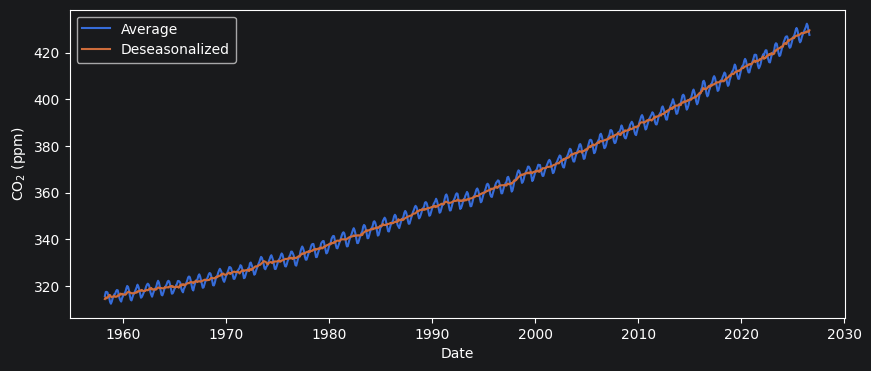

In [59]:
# Part 3
# Question 8, 9
# 10 width, 4 height
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(co2["date"], co2["average"], label='Average')
ax.plot(co2["date"], co2["deseasonalized"], label='Deseasonalized')
ax.set_xlabel('Date')
ax.set_ylabel('CO$_2$ (ppm)')
ax.legend()

print('Deseasonalized data removes seasonal fluctuations')

Text(0, 0.5, 'CH$_4$ (ppb)')

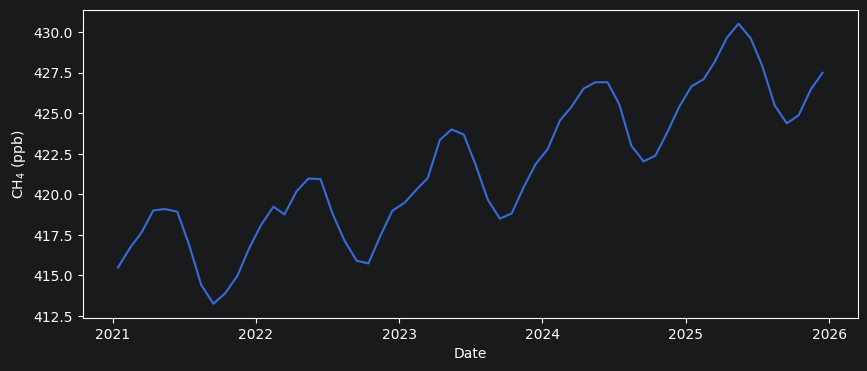

In [62]:
# Question 10
fig, ax = plt.subplots(figsize=(10, 4))
window = co2[(co2['year'] >= 2021) & (co2['year'] <= 2025)]
ax.plot(window["date"], window["average"])
ax.set_xlabel('Date')
ax.set_ylabel('CH$_4$ (ppb)')
print('The pattern for each year is a spike in the spring and a dip in the fall.')

Text(0, 0.5, 'Seasonal Difference in CO$_2$ (ppb)')

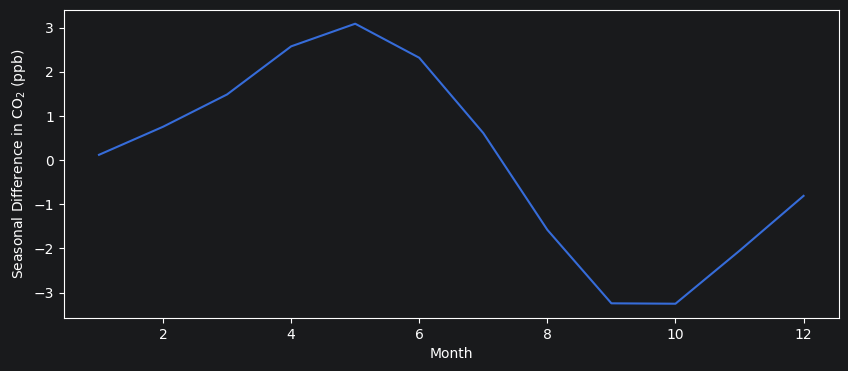

In [73]:
# Part 4
# Question 11, 12
co2['seasonal'] = co2['average'] - co2['deseasonalized']
seasonal_cycle = co2.groupby('month')['seasonal'].mean()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(seasonal_cycle.index, seasonal_cycle.values)
ax.set_xlabel('Month')
ax.set_ylabel('Seasonal Difference in CO$_2$ (ppb)')

print('CO2 peaks in may and dips in September and October')
print('In the northern hemisphere, vegetation grows in the spring and starts to die in the fall. Plants absorb carbon.')

Text(0, 0.5, 'Annual Growth of CO$_2$ (ppb)')

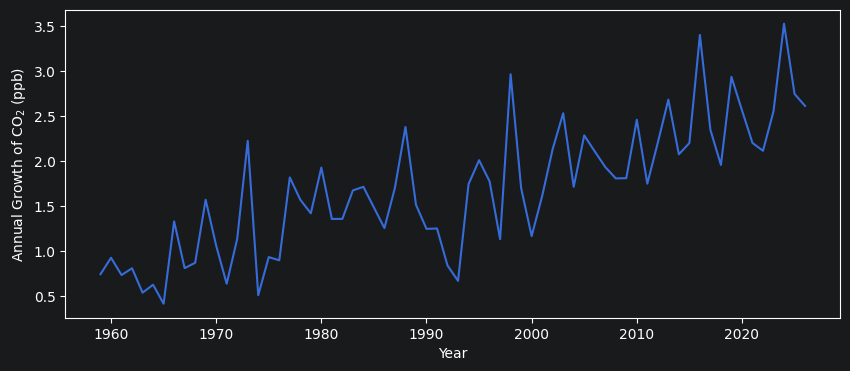

In [79]:
# Question 13
annual_mean = co2.groupby('year')['average'].mean()
annual_growth = annual_mean.diff().dropna()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(annual_growth.index, annual_growth.values)
ax.set_xlabel('Year')
ax.set_ylabel('Annual Growth of CO$_2$ (ppb)')

In [81]:
# Question 14
slope, intercept = np.polyfit(co2['decimal_date'], co2['average'], 1)
slope,intercept

(np.float64(1.6698925434436103), np.float64(-2965.7602627743604))

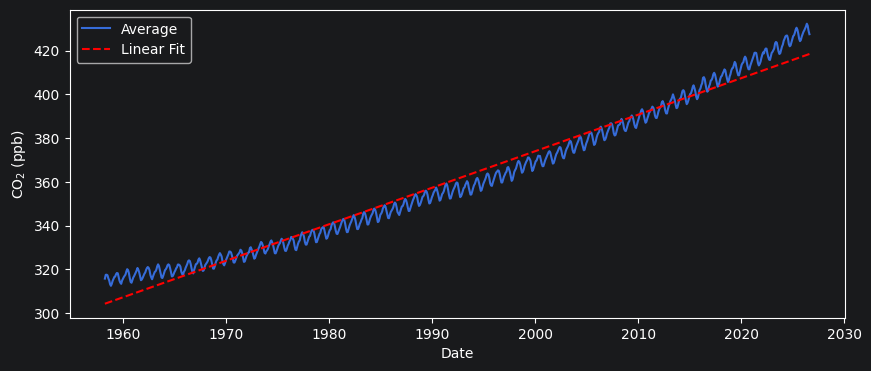

In [83]:
# Question 15
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(co2["date"], co2["average"], label='Average')
ax.plot(co2["date"], slope*co2['decimal_date'] + intercept, 'r--', label='Linear Fit')
ax.set_xlabel('Date')
ax.set_ylabel('CO$_2$ (ppb)')
ax.legend()

In [ ]:
print('The linear fit is not a good description of the data. It looks like there is a curve to the data that the linear fit does not account for. From 2020 onwards, it looks like the curve has surpassed the linear fit and so predicting into the future will not be very accurate.')